Aturan urutan tetangga: menaik menurut nama titik.

BFS (Breadth-First Search)
No  Diambil         Frontier setelahnya
1   Parkiran        [G3-1]
2   G3-1            [G1-1, G3-2]
3   G1-1            [G3-2, G1-2]
4   G3-2            [G1-2, G3-3]
5   G1-2            [G3-3, G1-3]
6   G3-3            [G1-3, G3-4]
7   G1-3            [G3-4, Perpus]
8   G3-4            [Perpus, Rooftop]
9   Perpus          [Rooftop]
10  Rooftop         []

Jalur         : Parkiran -> G3-1 -> G3-2 -> G3-3 -> G3-4 -> Rooftop
Biaya total   : 71 detik
Titik diambil : 10

DFS (Depth-First Search)
No  Diambil         Frontier setelahnya
1   Parkiran        [G3-1]
2   G3-1            [G1-1, G3-2]
3   G1-1            [G1-2, G3-2]
4   G1-2            [G1-3, G3-2]
5   G1-3            [Perpus, G3-2]
6   Perpus          [Rooftop, G3-2]
7   Rooftop         [G3-2]

Jalur         : Parkiran -> G3-1 -> G1-1 -> G1-2 -> G1-3 -> Perpus -> Rooftop
Biaya total   : 73 detik
Titik diambil : 7

UCS (Uniform-Cost Search)
No  Diambil

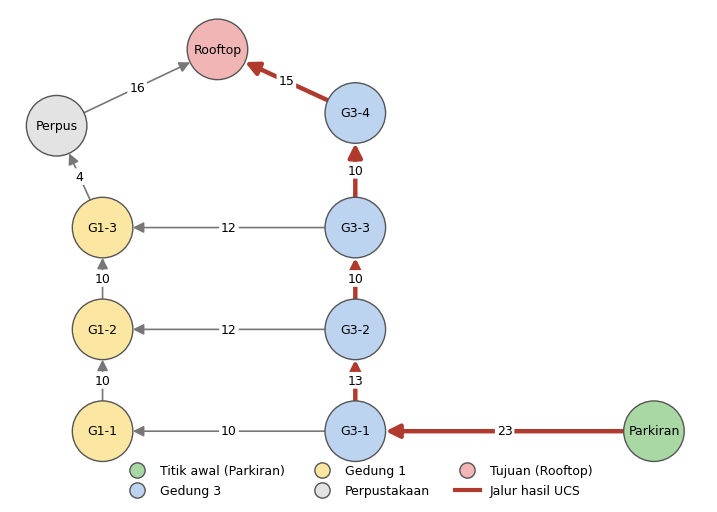

Gambar disimpan sebagai graf_rute.png


In [1]:
import heapq
from collections import deque

import matplotlib.pyplot as plt
import networkx as nx

JALAN = [
    ("Parkiran", "G3-1", 23),
    ("G3-1", "G1-1", 10),
    ("G3-1", "G3-2", 13),
    ("G1-1", "G1-2", 10),
    ("G3-2", "G1-2", 12),
    ("G3-2", "G3-3", 10),
    ("G1-2", "G1-3", 10),
    ("G3-3", "G1-3", 12),
    ("G3-3", "G3-4", 10),
    ("G1-3", "Perpus", 4),
    ("Perpus", "Rooftop", 16),
    ("G3-4", "Rooftop", 15),
]
AWAL = "Parkiran"
TUJUAN = "Rooftop"

tetangga = {}
for dari, ke, waktu in JALAN:
    tetangga.setdefault(dari, []).append((ke, waktu))
    tetangga.setdefault(ke, [])

for titik in tetangga:
    tetangga[titik].sort()


def waktu_ruas(a, b):
    for ke, w in tetangga[a]:
        if ke == b:
            return w


def hitung_biaya(jalur):
    return sum(waktu_ruas(jalur[i], jalur[i + 1]) for i in range(len(jalur) - 1))


def susun_jalur(induk, titik):
    jalur = []
    while titik is not None:
        jalur.append(titik)
        titik = induk[titik]
    return jalur[::-1]


def bfs():
    frontier = deque([AWAL])
    induk = {AWAL: None}
    langkah = []
    while frontier:
        titik = frontier.popleft()
        if titik == TUJUAN:
            langkah.append((titik, None, list(frontier)))
            break
        for ke, _ in tetangga[titik]:
            if ke not in induk:
                induk[ke] = titik
                frontier.append(ke)
        langkah.append((titik, None, list(frontier)))
    return langkah, susun_jalur(induk, TUJUAN)


def dfs():
    tumpukan = [(AWAL, None)]
    induk = {}
    dikunjungi = set()
    langkah = []
    while tumpukan:
        titik, asal = tumpukan.pop()
        if titik in dikunjungi:
            continue
        dikunjungi.add(titik)
        induk[titik] = asal
        if titik == TUJUAN:
            langkah.append((titik, None, [t for t, _ in reversed(tumpukan)]))
            break
        for ke, _ in reversed(tetangga[titik]):
            if ke not in dikunjungi:
                tumpukan.append((ke, titik))
        langkah.append((titik, None, [t for t, _ in reversed(tumpukan)]))
    return langkah, susun_jalur(induk, TUJUAN)


def tampil_frontier_ucs(antrean, terbaik, selesai):
    isi = sorted((b, t) for b, _, t in antrean if t not in selesai and b == terbaik[t])
    return [f"{t}({b})" for b, t in isi]


def ucs():
    antrean = [(0, 0, AWAL)]
    nomor = 1
    induk = {AWAL: None}
    terbaik = {AWAL: 0}
    selesai = set()
    langkah = []
    while antrean:
        biaya, _, titik = heapq.heappop(antrean)
        if titik in selesai:
            continue
        selesai.add(titik)
        if titik == TUJUAN:
            langkah.append((titik, biaya, tampil_frontier_ucs(antrean, terbaik, selesai)))
            break
        for ke, w in tetangga[titik]:
            biaya_baru = biaya + w
            if ke not in terbaik or biaya_baru < terbaik[ke]:
                terbaik[ke] = biaya_baru
                induk[ke] = titik
                heapq.heappush(antrean, (biaya_baru, nomor, ke))
                nomor += 1
        langkah.append((titik, biaya, tampil_frontier_ucs(antrean, terbaik, selesai)))
    return langkah, susun_jalur(induk, TUJUAN)


def cetak(judul, langkah, jalur):
    print("=" * 64)
    print(judul)
    print("=" * 64)
    print(f"{'No':<4}{'Diambil':<16}Frontier setelahnya")
    for no, (titik, biaya, frontier) in enumerate(langkah, start=1):
        nama = titik if biaya is None else f"{titik} ({biaya})"
        print(f"{no:<4}{nama:<16}[{', '.join(frontier)}]")
    print()
    print("Jalur         :", " -> ".join(jalur))
    print("Biaya total   :", hitung_biaya(jalur), "detik")
    print("Titik diambil :", len(langkah))
    print()


def semua_jalur(titik=AWAL, sejauh_ini=()):
    jalur = list(sejauh_ini) + [titik]
    if titik == TUJUAN:
        return [jalur]
    hasil = []
    for ke, _ in tetangga[titik]:
        if ke not in jalur:
            hasil += semua_jalur(ke, jalur)
    return hasil


print("Aturan urutan tetangga: menaik menurut nama titik.\n")

hasil = {}
for nama, fungsi in [
    ("BFS (Breadth-First Search)", bfs),
    ("DFS (Depth-First Search)", dfs),
    ("UCS (Uniform-Cost Search)", ucs),
]:
    langkah, jalur = fungsi()
    hasil[nama] = (langkah, jalur)
    cetak(nama, langkah, jalur)

print("=" * 64)
print("SEMUA JALUR DARI AWAL KE TUJUAN")
print("=" * 64)
for jalur in semua_jalur():
    print(f"{hitung_biaya(jalur):>4} detik | {' -> '.join(jalur)}")
print()

print("=" * 64)
print("PERBANDINGAN")
print("=" * 64)
print(f"{'Metode':<30}{'Biaya':<8}{'Titik diambil':<15}Jalur")
for nama, (langkah, jalur) in hasil.items():
    print(f"{nama:<30}{hitung_biaya(jalur):<8}{len(langkah):<15}{' -> '.join(jalur)}")
print()

POSISI = {
    "Rooftop": (2.8, 3.8),
    "Perpus": (1.4, 3.2),
    "G3-4": (4.0, 3.3),
    "G1-3": (1.8, 2.4),
    "G3-3": (4.0, 2.4),
    "G1-2": (1.8, 1.6),
    "G3-2": (4.0, 1.6),
    "G1-1": (1.8, 0.8),
    "G3-1": (4.0, 0.8),
    "Parkiran": (6.6, 0.8),
}


def warna_titik(titik):
    if titik == AWAL:
        return "#a9d8a5"
    if titik == TUJUAN:
        return "#f2b5b5"
    if titik.startswith("G3"):
        return "#bcd4f0"
    if titik.startswith("G1"):
        return "#fbe7a1"
    return "#e3e3e3"


jalur_ucs = hasil["UCS (Uniform-Cost Search)"][1]
ruas_jalur = set(zip(jalur_ucs, jalur_ucs[1:]))

graf = nx.DiGraph()
for dari, ke, waktu in JALAN:
    graf.add_edge(dari, ke, waktu=waktu)

fig, ax = plt.subplots(figsize=(9, 6))
ax.set_axis_off()

nx.draw_networkx_nodes(
    graf, POSISI, ax=ax, node_size=1900,
    node_color=[warna_titik(t) for t in graf.nodes], edgecolors="#555555",
)
nx.draw_networkx_labels(graf, POSISI, ax=ax, font_size=9)

ruas_lain = [e for e in graf.edges if e not in ruas_jalur]
nx.draw_networkx_edges(graf, POSISI, edgelist=ruas_lain, ax=ax, node_size=1900,
                       edge_color="#777777", width=1.2, arrowsize=16)
nx.draw_networkx_edges(graf, POSISI, edgelist=list(ruas_jalur), ax=ax, node_size=1900,
                       edge_color="#b03a2e", width=3.2, arrowsize=20)

label_waktu = {(d, k): w for d, k, w in JALAN}
nx.draw_networkx_edge_labels(
    graf, POSISI, edge_labels=label_waktu, ax=ax, font_size=9, rotate=False,
    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"),
)

keterangan = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#a9d8a5", markeredgecolor="#555", markersize=11, label="Titik awal (Parkiran)"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#bcd4f0", markeredgecolor="#555", markersize=11, label="Gedung 3"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#fbe7a1", markeredgecolor="#555", markersize=11, label="Gedung 1"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#e3e3e3", markeredgecolor="#555", markersize=11, label="Perpustakaan"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#f2b5b5", markeredgecolor="#555", markersize=11, label="Tujuan (Rooftop)"),
    plt.Line2D([0], [0], color="#b03a2e", linewidth=3, label="Jalur hasil UCS"),
]
ax.legend(handles=keterangan, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=9)

plt.savefig("graf_rute.png", dpi=200, bbox_inches="tight")
plt.show()
print("Gambar disimpan sebagai graf_rute.png")